$\textbf{\huge Computer Vision Project:}$ $\text{\LARGE Brain Tumor Detection}$

$\textbf{Step 1: Load Data}$

$\text{\footnotesize The dataset contains 7,200 human brain MRI images categorized into four classes:}$

<small>

* Glioma

* Meningioma

* Pituitary tumor

* No tumor

</small>

$\text{\footnotesize The dataset is balanced with 14000 images per class for training and 400 images per class for test.}$

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")

print("Path to dataset files:", path)

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: /Users/johanna/.cache/kagglehub/datasets/masoudnickparvar/brain-tumor-mri-dataset/versions/2


$\textbf{Step 2: Exploratory Data Analysis (EDA)}$

$\text{\footnotesize Inspecting the raw files to confirm dataset size, image dimensions and color format.}$

Folder names: ['Training', 'Testing']
Class names: ['pituitary', 'notumor', 'glioma', 'meningioma']
Number of files: 1400
Image size: (512, 512)
Image mode: L


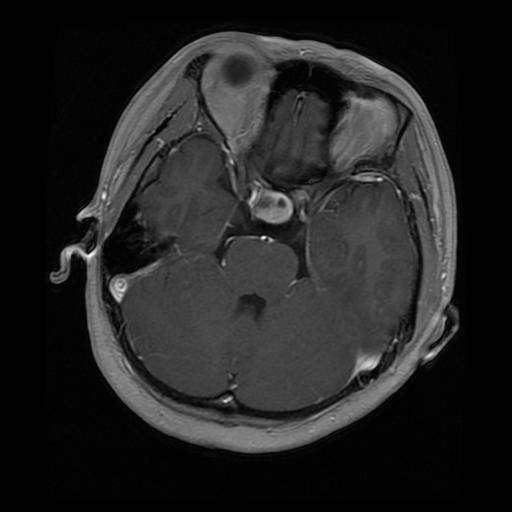

Number of files: 1400
Image size: (201, 251)
Image mode: RGB


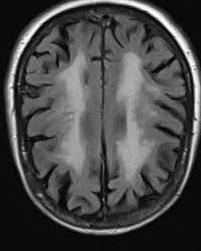

Number of files: 1400
Image size: (512, 512)
Image mode: L


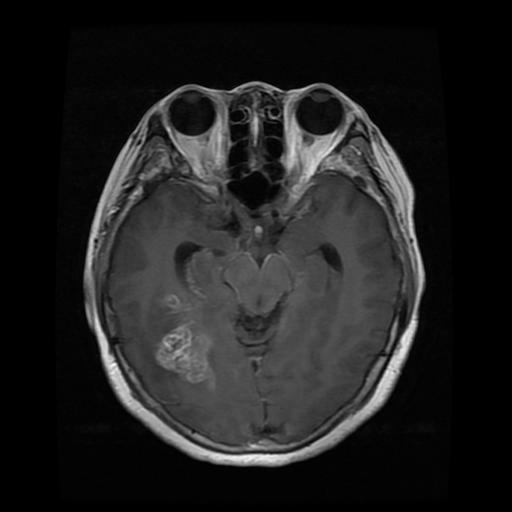

Number of files: 1400
Image size: (512, 512)
Image mode: L


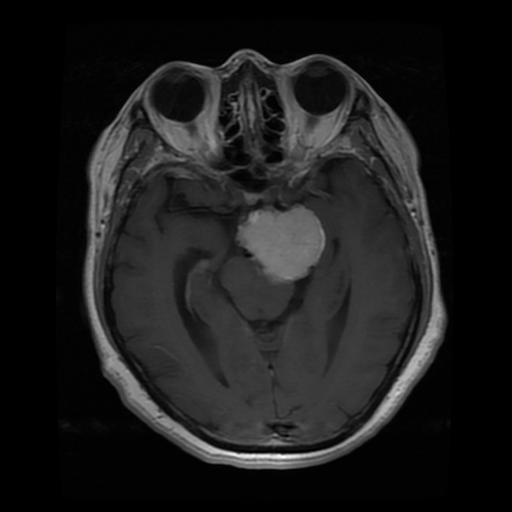

Class names: ['pituitary', 'notumor', 'glioma', 'meningioma']
Number of files: 400
Number of files: 400
Number of files: 400
Number of files: 400


In [ ]:
from PIL import Image
import os

# Check the folder names
folder_names = os.listdir(path)
print(f"Folder names: {folder_names}") # --> We have 'Training' and 'Testing'

# Check classes inside of the folders
for f in folder_names: 
    class_name = os.listdir(os.path.join(path, f))
    print(f"Class names: {class_name}")

    # Count number of files in each class
    for c in class_name:
        files = os.listdir(os.path.join(path, f, c))
        n_files = len(files)
        print(f"Number of files: {n_files}")

        # Check image dimensions, color format and visualise first image for each class
        if f == "Training":
            img = Image.open(os.path.join(path, f, c, files[0]))
            print(f"Image size: {img.size}")
            print(f"Image mode: {img.mode}")
            display(img)

$\textbf{Step 3: Preprocessing}$

<small>

* Resizing and normalization.

* Load folders and split training to training and validaiton data 80/20.

* Wrap them in a dataloader.

</small>

In [ ]:
import torchvision.transforms as T
from torchvision import datasets
from torch.utils.data import random_split
from torch.utils.data import DataLoader

# Resize images to dimesions 224x224, convert images to tensor and normalize pixels from 0-255 to 0-1
transform = T.Compose([T.Resize((224,224)), T.ToTensor()]) 

# Load training data and split: training and validation data 80/20
train_val_data = datasets.ImageFolder(
    os.path.join(path, 'Training'), 
    transform=transform
)

train_data, val_data = random_split(train_val_data, [0.8, 0.2])

# Load test data
test_data = datasets.ImageFolder(
    os.path.join(path, 'Testing'),
    transform=transform
)

# Wrap the dat into dataloader: receives a batch of images
train_dataloader = DataLoader(train_data, batch_size=24, shuffle = True)
val_dataloader = DataLoader(val_data, batch_size=24, shuffle=True)
test_dataloader = DataLoader(test_data, batch_size=24, shuffle=False)

$\textbf{Step 4: Model Setup}$

$\text{\footnotesize Initilize model with pre-trained weights, define device, loss function and optimizer.}$

In [ ]:
import torch
import torch.nn as nn
from torchvision.models import resnet34, ResNet34_Weights

# Intialize model with pre-trained weights and update number of classes
weights = ResNet34_Weights.DEFAULT
model = resnet34(weights=weights)
model.fc = nn.Linear(model.fc.in_features, 4) # Update classification layer with 4 classes

# Using GPU is available on computer, else uses CPU
device = torch.device("mps") if torch.backends.mps.is_available() else "cpu"
model = model.to(device)

# Define loss function and optimizer
loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001) # lr = 0.001 as default

$\textbf{Step 5: Training and Validation}$

$\textbf{Step 6: Evaluation}$

$\textbf{Step 7: Visualization}$